# 02 · Preprocessing, splits and noise augmentation
Code: `scripts/preprocess.py` (one parallel CPU pass, about 2 minutes on 120 cores) and `src/group9_ds_ai_lab/data/` (`audio.py`, `text.py`, `noise.py`, `dataset.py`).

### Pipeline
1. **Decode** each LibriSpeech utterance straight from the local Hugging Face arrow shards, which store the original 16 kHz FLAC. This avoids the `datasets`/`torchcodec` dependency and does not duplicate 982 h of audio.
2. **Standardise:** mono, 16 kHz (the resampler is only needed for ESC-50 at 44.1 kHz), length checks, per-file quality statistics.
3. **Normalise text:** one function for training labels *and* evaluation references. It upper-cases, keeps A–Z and the apostrophe, and collapses spaces.
4. **Filter training data:** keep 1–20 s utterances that CTC can align.
5. **Splits:** the official speaker-disjoint LibriSpeech splits, with leakage asserted.
6. **Noise banks:** MUSAN noise/music split *by file* 90/10 (train/val); ESC-50 is test-only.
7. **Fixed, seeded corruption manifests** for validation and test, so every model hears exactly the same noisy audio.
8. **On-the-fly training augmentation** (Model B): 20% clean, otherwise white/pink/MUSAN-noise/MUSAN-music at SNR ~ U[0, 20] dB.

### What changed from Milestones 2 and 3, and why
| M2/M3 | Now | Reason |
|---|---|---|
| Test set taken from train-clean-100 | official test-clean / test-other | base-960h had been trained on train-clean-100 (leakage) |
| Same noise types in train and test | brown + ESC-50 are **test-only** | measures robustness to *unseen* noise |
| 13 noisy copies stored on disk | augmentation computed on the fly | new noise every epoch, no disk blow-up |
| Apostrophes removed | apostrophes kept | they are in the model's vocabulary |
| Kaggle paths, `datasets==2.18` | local arrow shards read directly | runs on our server and is reproducible |

In [1]:
import sys, json, warnings
from pathlib import Path
cwd = Path.cwd()
REPO = next(p for p in (cwd, *cwd.parents) if (p / "src" / "group9_ds_ai_lab").is_dir())
sys.path.insert(0, str(REPO / "src"))
from group9_ds_ai_lab.utils.paths import *   # noqa  (all project paths)
setup_env()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, Audio
from group9_ds_ai_lab.utils.plotstyle import apply_style, SERIES, INK, INK2, GRID, SURF, MODEL_COLOR, MODEL_LABEL, NOISE_COLOR
apply_style(); warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
print("repo:", REPO)

repo: <repo root>


In [2]:
qc = json.load(open(MANIFESTS / "qc_summary.json"))
display(pd.Series({k: v for k, v in qc.items() if k != "noise_roles"}, name="value").to_frame())

,value
total_utts,"292,367.000"
decode_failed,0.000
empty_text,0.000
text_changed_by_norm,0.000
non_16k,0.000
multi_channel,0.000
ctc_infeasible,0.000
duplicate_ids,0.000
train_before_filter,"28,539.000"
train_after_filter,"28,538.000"


## Split manifests (Milestone 2 schema)

In [3]:
train, valid, test = (pd.read_csv(MANIFESTS / f"{s}.csv") for s in ("train", "valid", "test"))
display(train.head(3))
summary = pd.DataFrame({s: {"utterances": len(d), "hours": d.duration.sum()/3600, "speakers": d.speaker_id.nunique(),
                            "source": ", ".join(sorted(d.ls_split.unique()))} for s, d in [("train", train), ("valid", valid), ("test", test)]}).T
display(summary)

,audio_id,audio_path,text,duration,original_sample_rate,noise_type,snr_db,split,ls_split,shard,row,speaker_id,chapter_id
0,374-180298-0000,data/raw/librispeech/openslr___librispeech_asr...,CHAPTER SIXTEEN I MIGHT HAVE TOLD YOU OF THE B...,14.530,16000,clean,NaN,train,train.clean.100,data/raw/librispeech/openslr___librispeech_asr...,0,374,180298
1,374-180298-0001,data/raw/librispeech/openslr___librispeech_asr...,MARGUERITE TO BE UNABLE TO LIVE APART FROM ME ...,16.085,16000,clean,NaN,train,train.clean.100,data/raw/librispeech/openslr___librispeech_asr...,1,374,180298
2,374-180298-0002,data/raw/librispeech/openslr___librispeech_asr...,I WISHED ABOVE ALL NOT TO LEAVE MYSELF TIME TO...,13.295,16000,clean,NaN,train,train.clean.100,data/raw/librispeech/openslr___librispeech_asr...,2,374,180298


,utterances,hours,speakers,source
train,28538,100.584,251,train.clean.100
valid,5567,10.509,73,"validation.clean, validation.other"
test,5559,10.745,73,"test.clean, test.other"


## Leakage checks: utterances *and* speakers must be disjoint

In [4]:
for (a, na), (b, nb_) in [((train, "train"), (valid, "valid")), ((train, "train"), (test, "test")), ((valid, "valid"), (test, "test"))]:
    assert not set(a.audio_id) & set(b.audio_id), (na, nb_)
    assert not set(a.speaker_id) & set(b.speaker_id), (na, nb_)
    print(f"{na:5s} vs {nb_:5s}: 0 shared utterances, 0 shared speakers  ✓")
nf = pd.read_csv(MANIFESTS / "noise_files.csv")
assert not set(nf[nf.role == "train"].file) & set(nf[nf.role.isin(["val", "test"])].file)
print("noise files: train / val / test disjoint  ✓   | brown + ESC-50 never used in training  ✓")

train vs valid: 0 shared utterances, 0 shared speakers  ✓
train vs test : 0 shared utterances, 0 shared speakers  ✓
valid vs test : 0 shared utterances, 0 shared speakers  ✓
noise files: train / val / test disjoint  ✓   | brown + ESC-50 never used in training  ✓


## Text normalisation and CTC labels

In [5]:
from group9_ds_ai_lab.data.text import normalize_text, encode, VOCAB, ID2CH
for s in ["Don't stop, Mr. Smith!", "It's 5 o’clock", "HELLO   world"]:
    t = normalize_text(s); ids = encode(t)
    print(f"{s!r:28} -> {t!r:22} -> {ids[:12]}...")
print("vocab (32):", list(VOCAB))

"Don't stop, Mr. Smith!"     -> "DON'T STOP MR SMITH"  -> [14, 8, 9, 27, 6, 4, 12, 6, 8, 23, 4, 17]...
"It's 5 o’clock"             -> "IT'S O'CLOCK"         -> [10, 6, 27, 12, 4, 8, 27, 19, 15, 8, 19, 26]...
'HELLO   world'              -> 'HELLO WORLD'          -> [11, 5, 15, 15, 8, 4, 18, 8, 13, 15, 14]...
vocab (32): ['<pad>', '<s>', '</s>', '<unk>', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z']


## Noise banks

In [6]:
rows = []
for f in sorted(NOISE_DIR.glob("*.index.json")):
    idx = json.load(open(f)); rows.append({"bank": f.name.replace(".index.json", ""), "clips": len(idx["files"]),
                                           "hours": sum(idx["lengths"]) / 16000 / 3600})
display(pd.DataFrame(rows))
print(json.dumps(json.load(open(PROCESSED / "augmentation" / "noise_params.json")), indent=1))

,bank,clips,hours
0,esc50_test,1999,2.776
1,musan_music_train,594,38.648
2,musan_music_val,66,3.966
3,musan_noise_train,836,5.780
4,musan_noise_val,93,0.446


{
 "sample_rate": 16000,
 "train_noise": {
  "types": [
   "white",
   "pink",
   "musan_noise",
   "musan_music"
  ],
  "p_clean": 0.2,
  "snr_db_uniform": [
   0,
   20
  ],
  "musan_files": "90% of MUSAN noise+music (file-level split, seed 42)"
 },
 "valid_noise": {
  "types": [
   "white",
   "pink",
   "musan_noise",
   "musan_music"
  ],
  "snr_db": [
   0,
   5,
   10,
   20
  ],
  "musan_files": "held-out 10%"
 },
 "test_noise": {
  "types": [
   "white",
   "pink",
   "brown",
   "esc50"
  ],
  "snr_db": [
   20,
   10,
   5,
   0,
   "clean"
  ],
  "held_out_types": [
   "brown",
   "esc50"
  ],
  "seen_reference_types": [
   "white",
   "pink"
  ]
 },
 "mixing": "noise scaled to P_speech / 10^(SNR/10) over the whole utterance, no clipping",
 "text_normalisation": "upper-case, keep A-Z and apostrophe, collapse whitespace (32-char wav2vec2 vocab)",
 "seed": 42
}


## SNR mixing is exact
Noise is scaled to `P_speech / 10^(SNR/10)` and nothing is clipped, so the measured SNR matches the target exactly.

In [7]:
from group9_ds_ai_lab.data.audio import ArrowAudioReader
from group9_ds_ai_lab.data.noise import make_noise, mix_at_snr
rd = ArrowAudioReader(); rng = np.random.default_rng(1)
x = rd.load(test.shard[0], test.row[0]); out = []
for kind, part in [("white", "train"), ("pink", "train"), ("musan_noise", "train"), ("musan_music", "train"), ("brown", "test"), ("esc50", "test")]:
    for snr in (20, 10, 5, 0):
        n, info = make_noise(kind, len(x), rng, part=part); y = mix_at_snr(x, n, snr)
        out.append({"noise": kind, "target_snr": snr, "measured_snr": 10*np.log10(np.mean(x**2) / np.mean((y - x)**2))})
display(pd.DataFrame(out).pivot(index="noise", columns="target_snr", values="measured_snr").round(3))

target_snr,0,5,10,20
noise,,,,
brown,-0.000,5.000,10.000,20.000
esc50,-0.000,5.000,10.000,20.000
musan_music,-0.000,5.000,10.000,20.000
musan_noise,-0.000,5.000,10.000,20.000
pink,-0.000,5.000,10.000,20.000
white,-0.000,5.000,10.000,20.000


## On-the-fly augmentation used by Model B

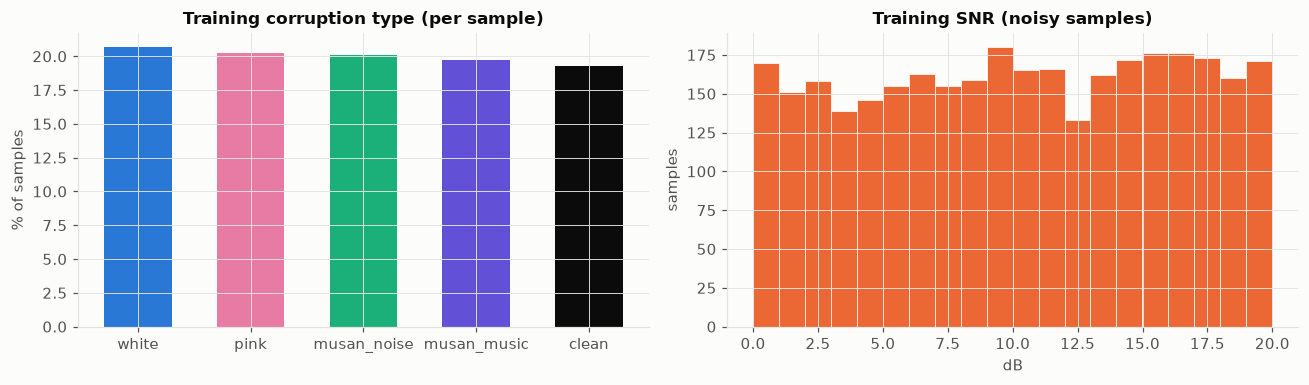

In [8]:
from group9_ds_ai_lab.data.noise import TrainAugmenter
aug = TrainAugmenter(p_clean=.2, snr_range=(0, 20)); draws = []
for i in range(4000):
    r = np.random.default_rng(i)
    if r.random() < aug.p_clean: draws.append(("clean", np.nan)); continue
    draws.append((aug.types[int(r.integers(len(aug.types)))], float(r.uniform(*aug.snr_range))))
d = pd.DataFrame(draws, columns=["type", "snr"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
vc = d.type.value_counts(); axes[0].bar(vc.index, vc.values / len(d) * 100, color=[NOISE_COLOR[k] for k in vc.index], width=.6)
axes[0].set(title="Training corruption type (per sample)", ylabel="% of samples")
axes[1].hist(d.snr.dropna(), bins=20, color=SERIES[1], edgecolor=SURF, lw=.5); axes[1].set(title="Training SNR (noisy samples)", xlabel="dB", ylabel="samples")
plt.tight_layout(); plt.show()

## Fixed evaluation conditions

In [9]:
ve = pd.read_csv(MANIFESTS / "valid_eval.csv"); tc = pd.read_csv(MANIFESTS / "test_conditions.csv")
print(f"validation (checkpoint selection): {len(ve):,} rows = 2,000 dev utterances x (clean + 1 seeded training-type noise from held-out MUSAN files)")
display(ve.groupby(["noise_type"]).size().rename("rows").to_frame().T)
print(f"test grid: {len(tc):,} rows = {tc.audio_id.nunique():,} test utterances x 17 conditions")
display(tc.assign(snr=tc.snr_db.fillna(-1).astype(int).astype(str).replace("-1", "clean"))
          .groupby(["noise_type", "snr"]).size().unstack(fill_value=0))

validation (checkpoint selection): 4,000 rows = 2,000 dev utterances x (clean + 1 seeded training-type noise from held-out MUSAN files)


noise_type,clean,musan_music,musan_noise,pink,white
rows,2000,506,496,491,507


test grid: 94,503 rows = 5,559 test utterances x 17 conditions


snr,0,10,20,5,clean
noise_type,,,,,
brown,5559,5559,5559,5559,0
clean,0,0,0,0,5559
esc50,5559,5559,5559,5559,0
pink,5559,5559,5559,5559,0
white,5559,5559,5559,5559,0


## A batch, as the model sees it

In [10]:
import torch
from group9_ds_ai_lab.data.dataset import ASRDataset, collate_ctc, DurationBatchSampler
ds = ASRDataset(train.head(64), augmenter=aug)
bs = DurationBatchSampler(ds.durations, 120, shuffle=True)
batch = collate_ctc([ds[i] for i in next(iter(bs))])
for k, v in batch.items(): print(f"{k:14s} {tuple(v.shape)} {v.dtype}")
print("frames per utterance:", (batch['input_lengths'] // 320).tolist()[:6], "...  labels padded with -100 (ignored by CTC)")

input_values   (4, 135601) torch.float32
labels         (4, 129) torch.int64
input_lengths  (4,) torch.int64
index          (4,) torch.int64
frames per utterance: [423, 415, 201, 148] ...  labels padded with -100 (ignored by CTC)
